In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [2]:
import scvi

In [3]:
scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


Last run with scvi-tools version: 1.3.3


In [4]:
print("Last run with scanpy version:", sc.__version__)

Last run with scanpy version: 1.11.4


In [5]:
sb.set_palette('colorblind')

In [6]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [7]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Load data

In [8]:
# object from POOL_TF.A01.v02.load_data.ipynb
adata = sc.read('write/pool_tf_entire_data_raw_count_v2.h5ad')

In [9]:
adata.obs['10x_kit'] = '5_v3.0'

## Preprocessing

In [10]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [11]:
adata.raw = adata  # keep full dimension safe
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer="counts",
    subset=False,
    batch_key="file",  # Change depending on the batch key for your dataset
)

In [12]:
# Save preprocessed data for later use
adata.write_h5ad("write/pool_preprocessed_scvi_v3.h5ad")

In [8]:
adata = sc.read("write/pool_preprocessed_scvi_v3.h5ad")

# scVI integration

In [9]:
scvi.model.SCVI.setup_anndata(adata, layer="counts")

In [10]:
model = scvi.model.SCVI(adata, n_layers=2, n_latent=30, gene_likelihood="nb")

In [11]:
model.train()

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.
/home/cs565/.conda/envs/skeleton/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Training:   0%|          | 0/82 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=82` reached.


In [12]:
SCVI_LATENT_KEY = "X_scVI"
adata.obsm[SCVI_LATENT_KEY] = model.get_latent_representation()

In [13]:
sc.pp.neighbors(adata, use_rep=SCVI_LATENT_KEY, random_state=1712)

In [14]:
sc.tl.umap(adata, 
           #min_dist=0.3, 
           random_state=1712)

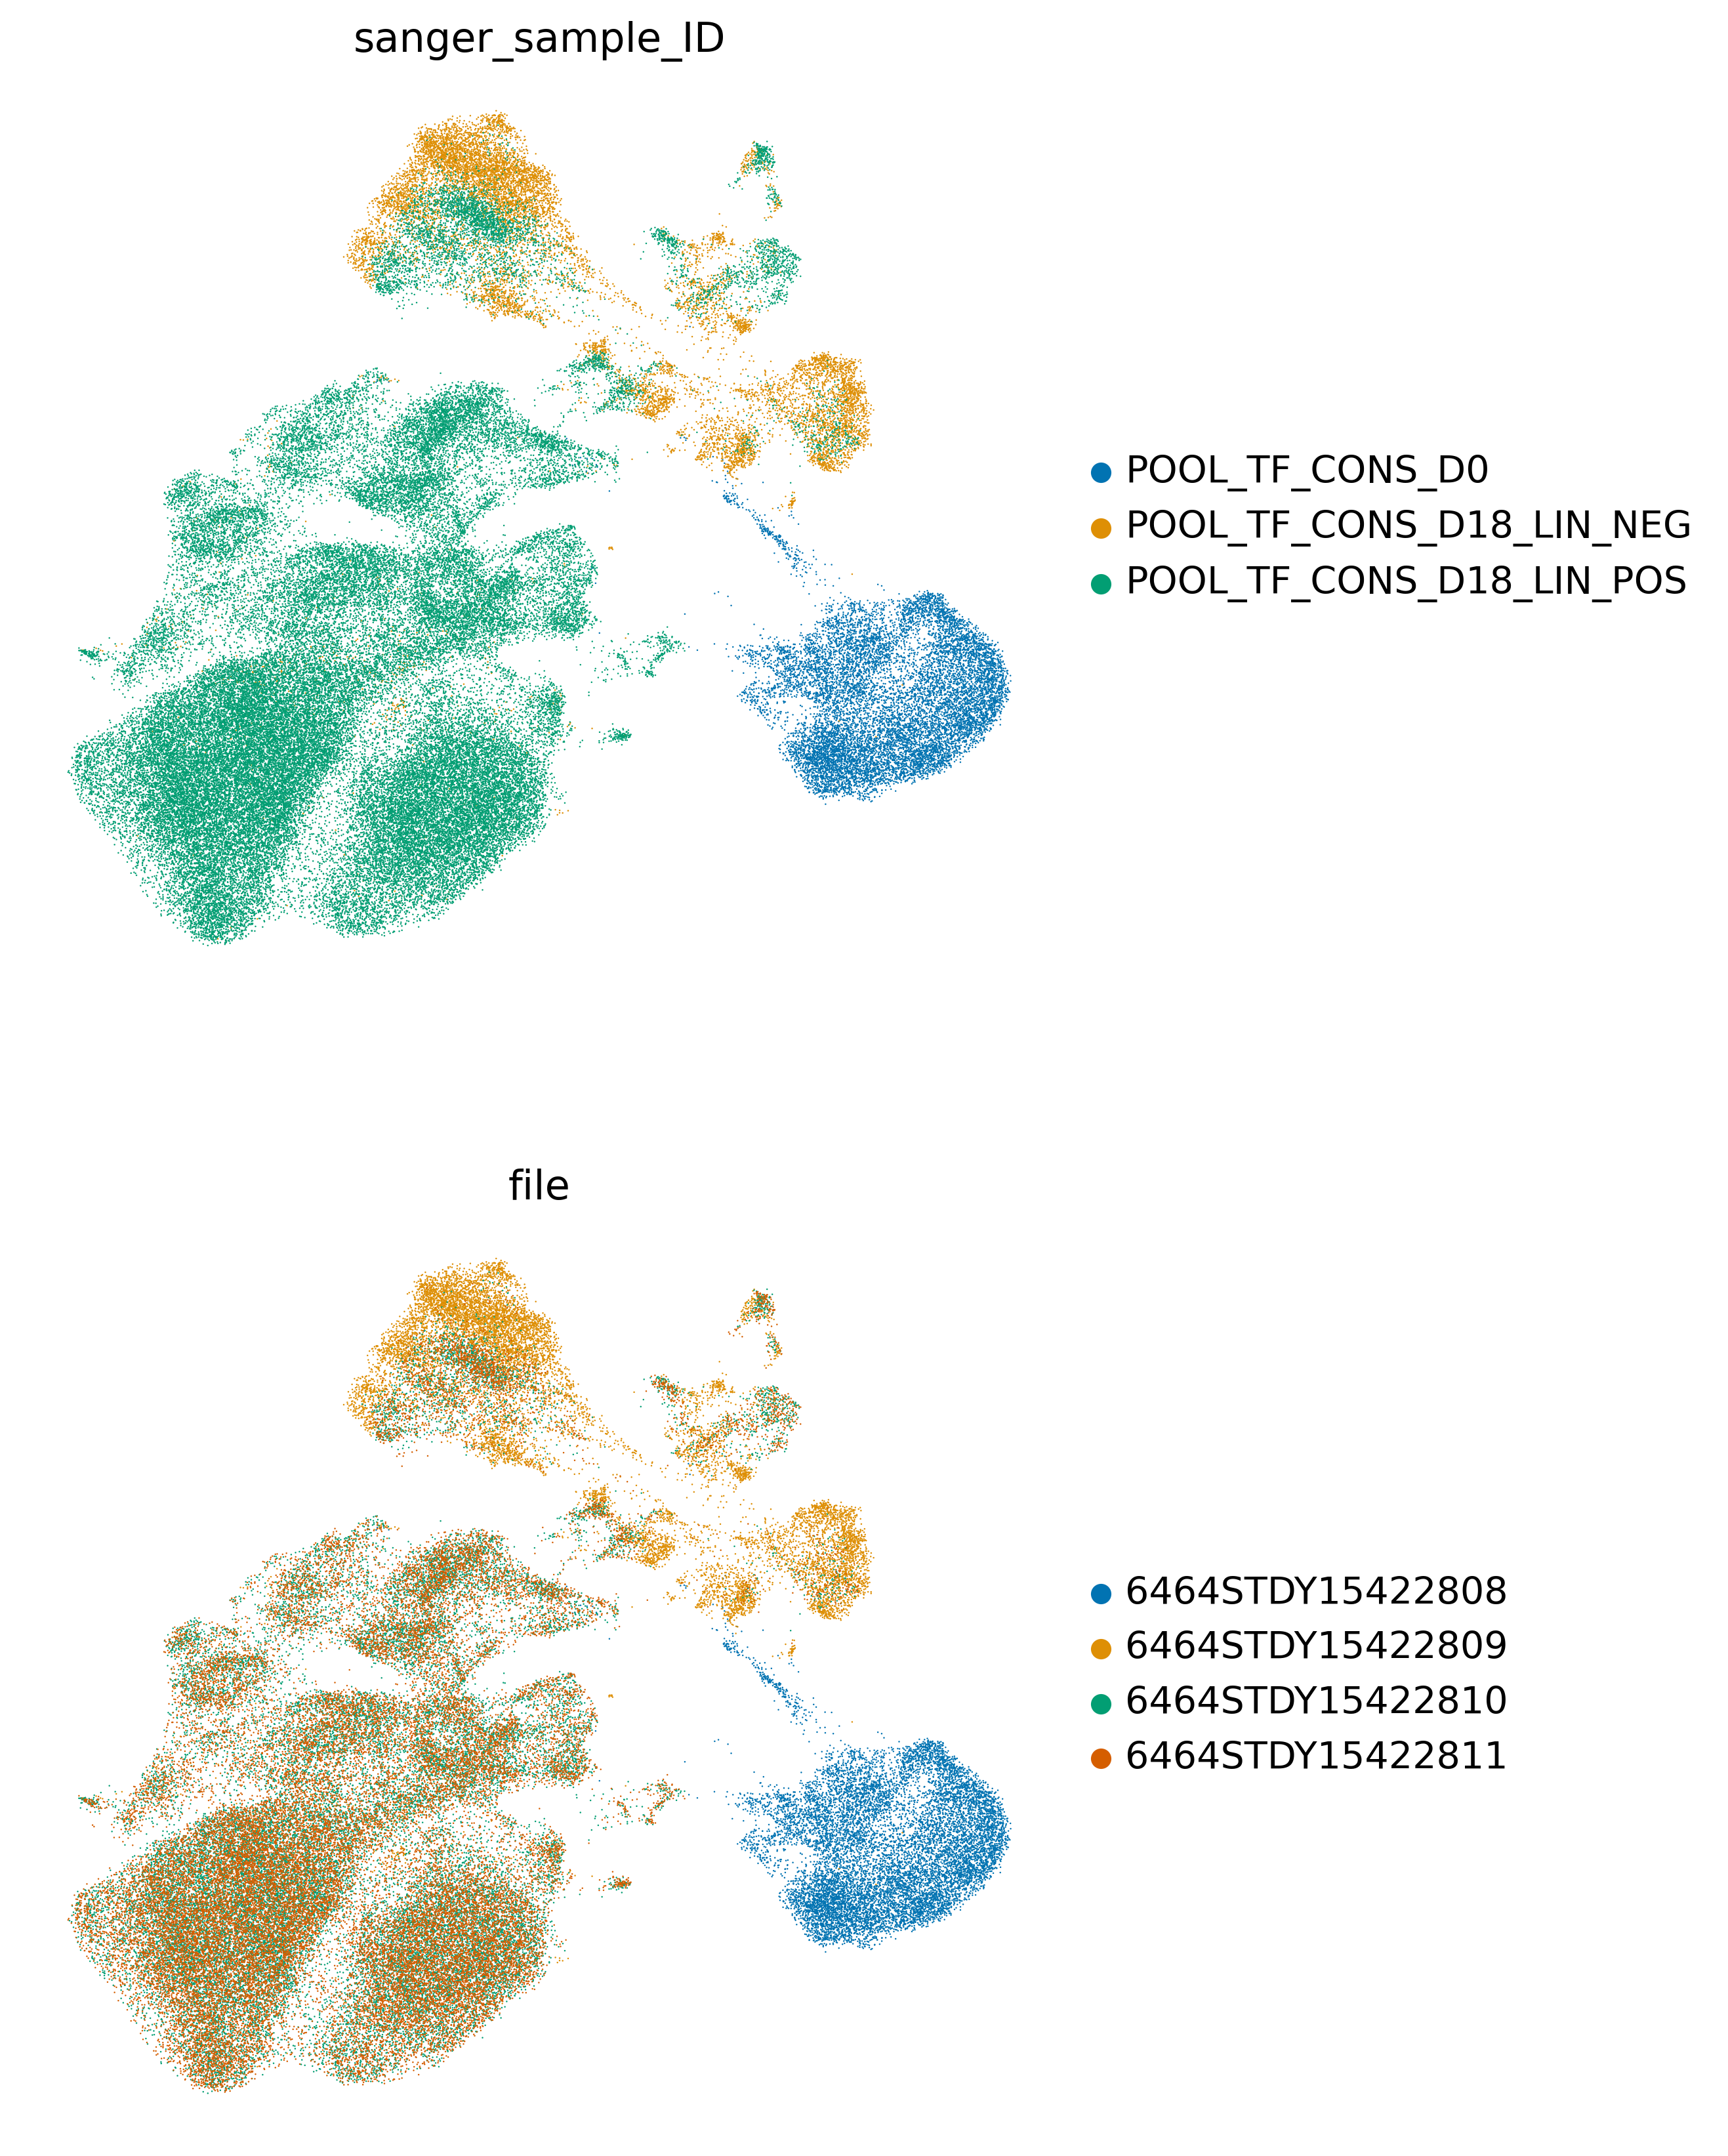

In [15]:
sc.pl.umap(
    adata,
    color=['sanger_sample_ID','file'],
    frameon=False,
    ncols=1,
)

In [16]:
sc.tl.leiden(adata, resolution =1)

/tmp/ipykernel_2834694/1875419978.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution =1)


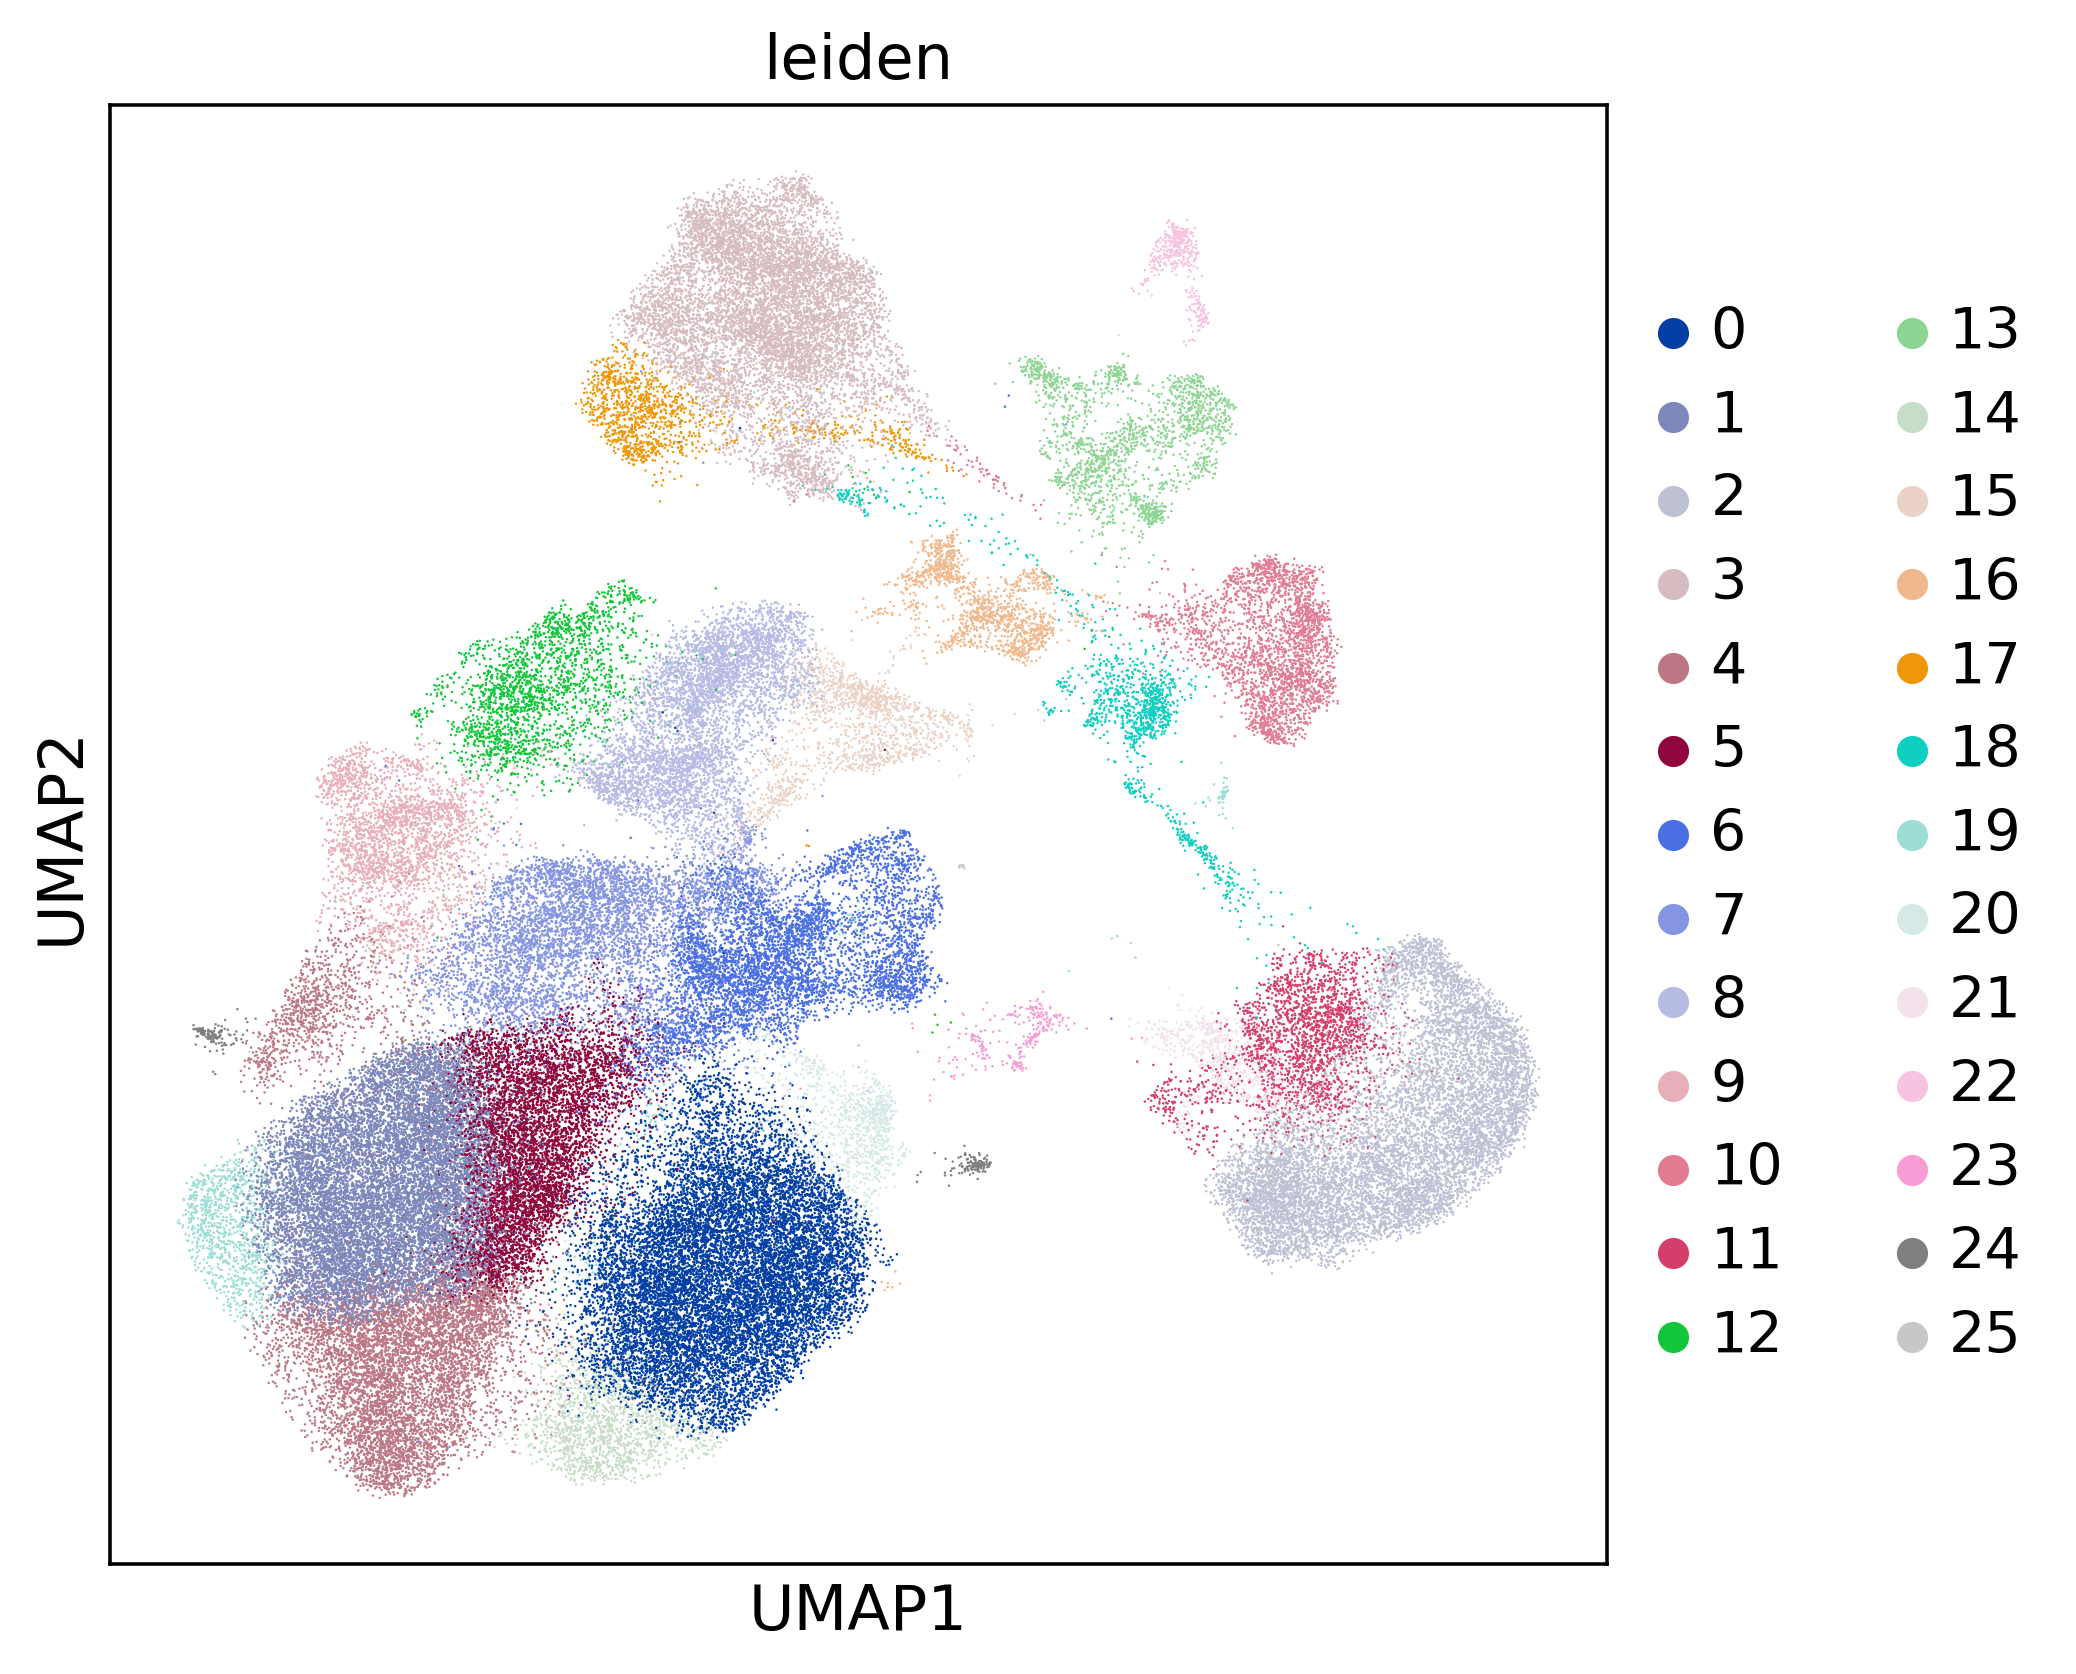

In [17]:
sc.pl.umap(adata, color='leiden')

In [18]:
adata.write_h5ad("write/pool_scvi_v2.h5ad")

In [ ]:
adata = sc.read("write/pool_scvi_v2.h5ad")